In [1]:
#from bai_utils import *
from tbp_utils_glm import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns
from collections import defaultdict
from sklearn.preprocessing import normalize
import ipdb

In [2]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2, scale=1):

    theta = (2*np.random.rand(p)-1)
    theta = theta / np.linalg.norm(theta)
    theta = scale * theta
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    return x, y, theta

In [103]:
x, y, theta = gen_data(100, p=2, scale=3)
intercept = np.random.rand(1)[0]
#x = x[np.abs(expit(x @ theta + intercept) - 0.3) > 0.2]
x = x[np.abs(expit(x @ theta + intercept) - 0.5) > 0.1]
x = x[expit(x @ theta + intercept) < 0.9]
x = x[expit(x @ theta + intercept) > 0.1]

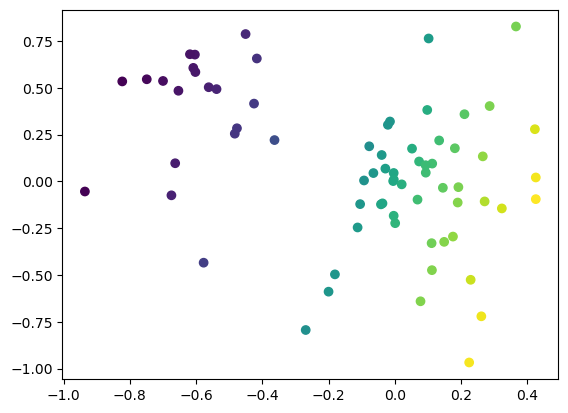

In [105]:
f = x @ theta
p = expit(f)
plt.scatter(x[:,0],x[:,1], c = p)

In [106]:
m, d = x.shape
prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
                "intercept": 0
              }

prob = logistic_discover(**prob_dict)

In [107]:
prob_t = deepcopy(prob)
solver = linear_solver(prob_t, 0.3, 0.01)
g_arms, perf, tau = solver.run(3000)

In [108]:
g_arms, perf, tau

(array([ 1,  2,  4,  5,  6,  7, 10, 11, 12, 13, 14, 15, 17, 20, 22, 23, 24,
        27, 28, 29, 30, 31, 32, 36, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47,
        48, 49, 50, 52, 53, 54, 55, 56, 59, 60, 61, 62, 64, 65, 66, 69]),
 (0, 0),
 nan)

In [109]:
prob_t = deepcopy(prob)
solver = lazy_TS(prob_t, 0.3, 0.01)
g_arms, perf, tau = solver.run(3000, 0.05)

In [110]:
g_arms, perf, tau

(array([ 1,  2,  4,  5,  6,  7, 10, 11, 12, 13, 14, 15, 17, 20, 22, 23, 24,
        27, 28, 29, 30, 31, 32, 36, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47,
        48, 49, 50, 52, 53, 54, 55, 56, 59, 60, 61, 62, 64, 65, 66, 69]),
 (0, 0),
 nan)

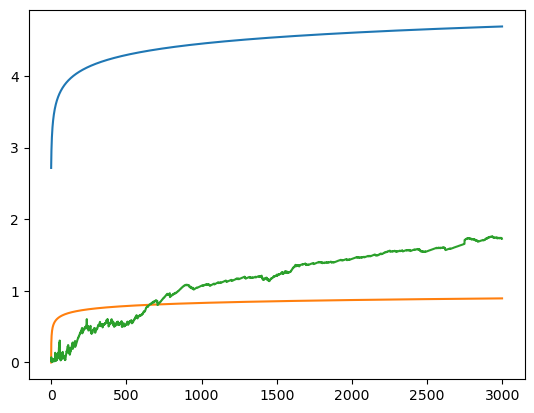

In [111]:
t = np.arange(1,3000)
delta = 0.05
plt.plot(np.sqrt(solver.prob.d * np.log((1 + t) / delta)))#
plt.plot(np.sqrt(.1*np.log(t)))
plt.plot(solver.ratio_hist)#

(array([1.000e+00, 0.000e+00, 0.000e+00, 1.963e+03, 1.000e+00, 0.000e+00,
        7.150e+02, 0.000e+00, 2.950e+02, 2.500e+01]),
 array([ 0. ,  6.9, 13.8, 20.7, 27.6, 34.5, 41.4, 48.3, 55.2, 62.1, 69. ]),
 <BarContainer object of 10 artists>)

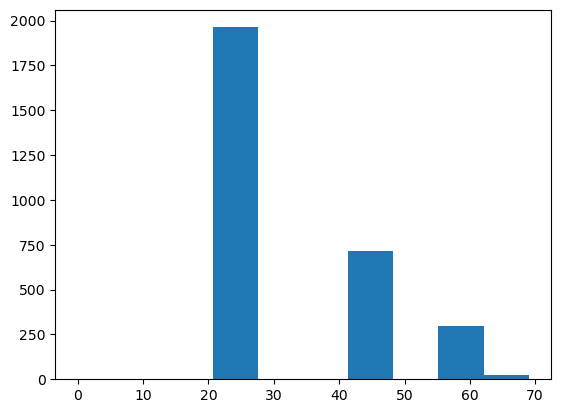

In [112]:
plt.hist(np.array(solver.prob.actions))

In [113]:
prob_t = deepcopy(prob)
solver = GLGapE(prob_t, 0.3, 0.01, 20)
g_arms, perf, tau = solver.run(3000, 0.05, 0)

In [114]:
g_arms, perf, tau

(array([ 1,  2,  4,  5,  6,  7, 10, 11, 12, 13, 14, 15, 17, 20, 22, 23, 24,
        27, 28, 29, 30, 31, 32, 36, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47,
        48, 49, 50, 52, 53, 54, 55, 56, 59, 60, 61, 62, 64, 65, 66, 69]),
 ((0, 0), (0, 0)),
 nan)

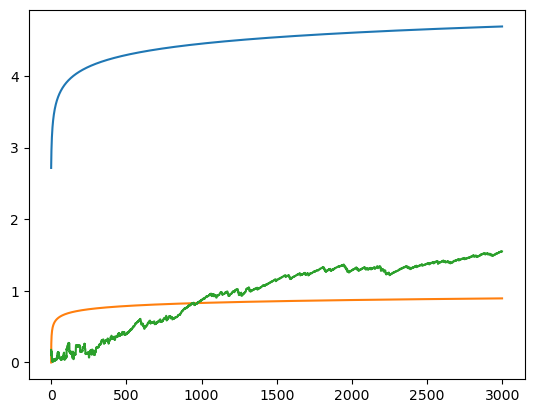

In [115]:
t = np.arange(1,3000)
delta = 0.05
plt.plot(np.sqrt(solver.prob.d * np.log((1 + t) / delta)))#
plt.plot(np.sqrt(.1*np.log(t)))
plt.plot(solver.ratio_hist)#

(array([3.600e+01, 0.000e+00, 1.000e+00, 0.000e+00, 4.580e+02, 0.000e+00,
        0.000e+00, 1.360e+03, 0.000e+00, 1.145e+03]),
 array([26. , 30.3, 34.6, 38.9, 43.2, 47.5, 51.8, 56.1, 60.4, 64.7, 69. ]),
 <BarContainer object of 10 artists>)

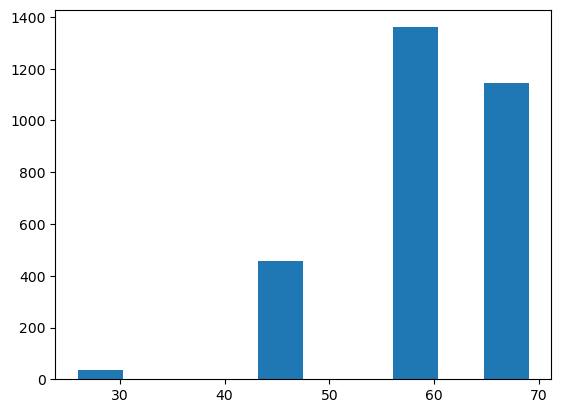

In [116]:
plt.hist(np.array(solver.prob.actions))

In [117]:
prob_t = deepcopy(prob)
solver = glm_rage(prob_t, 0.3, 0.01)
g_arms, perf, tau = solver.run(4000000, 0.05, 0)

g_arms, perf, tau

86.41748940655775
96.55984884980091
74.74358016910416
46.37554208104897
47.943473491980775


(array([ 1,  2,  4,  5,  6,  7, 10, 11, 12, 13, 14, 15, 17, 20, 22, 23, 24,
        27, 28, 29, 30, 31, 32, 36, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47,
        48, 49, 50, 52, 53, 54, 55, 56, 59, 60, 61, 62, 64, 65, 66, 69]),
 ((0, 0), (0, 0)),
 347)

In [118]:
solver.theta_hat

array([ 2.92976295, -1.06261381])

In [119]:
theta

array([ 2.93775333, -0.60795177])

(array([1000.,    1.,    1.,    0.,    1.,    2.,    0.,    2.,    1.,
           1.]),
 array([0. , 0.7, 1.4, 2.1, 2.8, 3.5, 4.2, 4.9, 5.6, 6.3, 7. ]),
 <BarContainer object of 10 artists>)

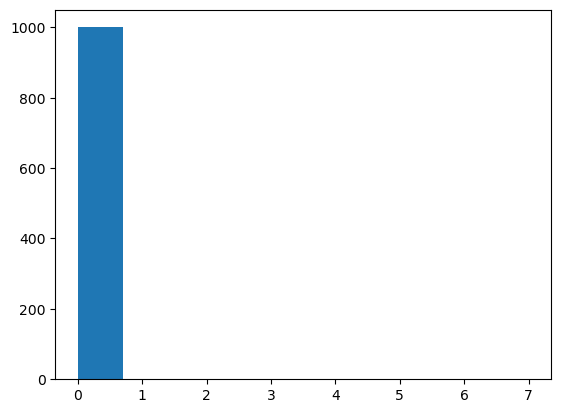

In [81]:
plt.hist(np.array(solver.prob.actions))

In [44]:
expit(solver.prob.x @ solver.theta_hat)[expit(solver.prob.x @ solver.prob.theta)<.3] <.3

array([], dtype=bool)

In [ ]:
expit(solver.prob.x @ solver.prob.theta)>.3

In [ ]:
solver.A

In [ ]:
(x[:,None,:] @ np.eye(2) @ x[:,:,None]).flatten()

In [ ]:
expit(x[g_arms] @ theta) 

In [ ]:
((expit(solver.prob.x @ solver.prob.theta) + 0.01)[g_arms] < 0.3).sum()

In [ ]:
solver.prob.x @ solver.theta_hat

In [ ]:
theta

In [ ]:
solver.prob.theta, intercept, solver.theta_hat, solver.intercept_hat

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
clf = LogisticRegression(random_state=0, penalty='none')

In [ ]:
clf.fit(x, y)

In [ ]:
clf.coef_, clf.intercept_

In [ ]:
y = np.random.binomial(1,expit(x @ theta + intercept))